# Preditivo Ind40

Projeto de classificação de falhas industriais. Minha formação em Engenharia Mecânica pode contribuir na interpretação de algumas das medições, sem substituir as evidências dos dados.

**Estado atual:** As sete fases foram executadas. A documentação e o vídeo da entrega estão em revisão.

## Fase 1 — Análise Exploratória

### Carregamento

Leio o CSV fornecido pela disciplina usando um caminho relativo em `data/`, permitindo executar o projeto em outro computador. `head()` confere os primeiros registros. O alvo é `falha_maquina`; identificadores e as cinco colunas que descrevem causas de falha não serão usados como preditores.

In [38]:
import pandas as pd

dados_maq = pd.read_csv("data/manutencao_preditiva.csv")
dados_maq.head()

,udi,id_produto,tipo,temperatura_ar_k,temperatura_processo_k,velocidade_rotacao_rpm,torque_nm,desgaste_ferramenta_min,falha_maquina,falha_twf,falha_hdf,falha_pwf,falha_osf,falha_rnf
0,1,M14860,M,298.1,308.6,1551.0,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408.0,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498.0,49.4,5,0,0,0,0,0,0
3,4,L47183,L,NaN,NaN,NaN,NaN,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408.0,40.0,9,0,0,0,0,0,0


### Dimensões

Verifico o número de linhas e colunas antes das transformações para acompanhar eventuais exclusões de registros.

In [39]:
dados_maq.shape

(10000, 14)

### Tipos de dados

Verifico como o Pandas interpretou cada coluna. Um identificador numérico não será tratado como uma medição física.

In [40]:
dados_maq.dtypes

,0
udi,int64
id_produto,object
tipo,object
temperatura_ar_k,float64
temperatura_processo_k,float64
velocidade_rotacao_rpm,float64
torque_nm,float64
desgaste_ferramenta_min,int64
falha_maquina,int64
falha_twf,int64


### Estatística descritiva

Uso `describe()` para comparar contagem de valores preenchidos, média, mediana, dispersão e extremos. Essas medidas orientam o diagnóstico das variáveis numéricas.

In [41]:
dados_maq.describe()

,udi,temperatura_ar_k,temperatura_processo_k,velocidade_rotacao_rpm,torque_nm,desgaste_ferramenta_min,falha_maquina,falha_twf,falha_hdf,falha_pwf,falha_osf,falha_rnf
count,10000.00000,9500.000000,9500.000000,9500.000000,9500.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000
mean,5000.50000,300.002158,310.000895,1539.245263,39.974168,107.951000,0.033900,0.004600,0.011500,0.009500,0.009800,0.00190
std,2886.89568,2.001689,1.486432,180.273589,9.995453,63.654147,0.180981,0.067671,0.106625,0.097009,0.098514,0.04355
min,1.00000,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
25%,2500.75000,298.300000,308.800000,1423.000000,33.100000,53.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
50%,5000.50000,300.100000,310.100000,1504.000000,40.100000,108.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
75%,7500.25000,301.500000,311.100000,1613.000000,46.700000,162.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
max,10000.00000,304.500000,313.800000,2886.000000,76.600000,253.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000


### Valores ausentes

`isna().sum()` conta as ausências sem alterar a tabela. As duas temperaturas, rotação e torque têm 500 valores ausentes cada, equivalentes a 5% da base por coluna. Não somo essas contagens para concluir quantas linhas estão afetadas, pois as ausências podem coincidir.

In [42]:
dados_maq.isna().sum()

,0
udi,0
id_produto,0
tipo,0
temperatura_ar_k,500
temperatura_processo_k,500
velocidade_rotacao_rpm,500
torque_nm,500
desgaste_ferramenta_min,0
falha_maquina,0
falha_twf,0


### Distribuição da classe alvo

Mostro tanto contagens como percentuais. `normalize=True` calcula proporções e a multiplicação por 100 converte para percentual. Uso `display()` para exibir os dois resultados na mesma célula.

In [43]:
display(dados_maq["falha_maquina"].value_counts())
display(dados_maq["falha_maquina"].value_counts(normalize=True) * 100)

,count
falha_maquina,
0,9661
1,339


,proportion
falha_maquina,
0,96.61
1,3.39


A base contém 9.661 registros normais (96,61%) e 339 falhas (3,39%). As classes são desbalanceadas. Prever sempre normal teria alta acurácia, mas deixaria passar todas as falhas, produzindo **falsos negativos**. Esse resultado justifica o balanceamento exclusivamente do treino e uma interpretação crítica da acurácia.

### Contagens reutilizáveis

Guardo a quantidade de registros por classe para usar no gráfico sem digitar manualmente os valores.

In [44]:
contagem_classes = dados_maq["falha_maquina"].value_counts()
contagem_classes

,count
falha_maquina,
0,9661
1,339


### Gráfico de barras

Comparo a quantidade de registros normais e com falha. O eixo vertical representa contagem; as categorias são classes, não medições contínuas.

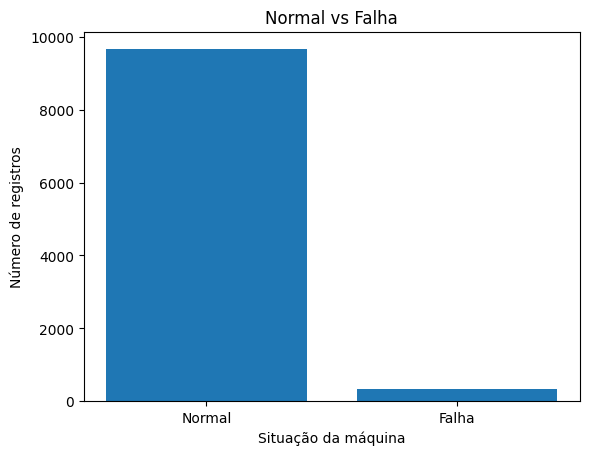

In [45]:
import matplotlib.pyplot as plt

categorias = ["Normal", "Falha"]
quantidades = [contagem_classes[0], contagem_classes[1]]

plt.bar(categorias, quantidades)
plt.title("Normal vs Falha")
plt.xlabel("Situação da máquina")
plt.ylabel("Número de registros")
plt.show()

O gráfico de barras "Normal vs Falha" demonstra o que já foi mencionado, a base de dados apresenta um número muito superior de registros "normais" do que de registros de falha

### Histograma da rotação

Uso 20 intervalos para investigar a concentração e as caudas da rotação. `dropna()` desconsidera as ausências somente na seleção usada pelo gráfico; a base original permanece intacta.

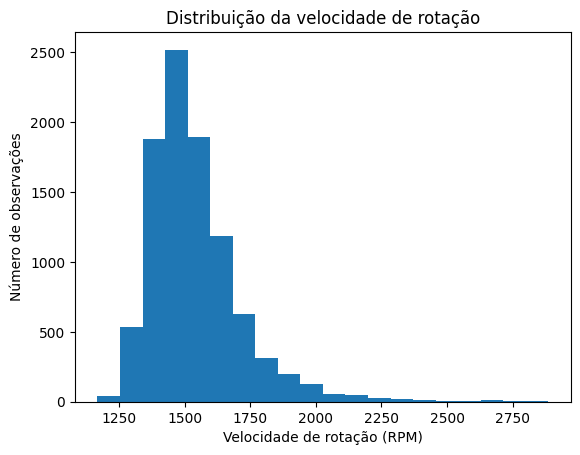

In [46]:
rotacao = dados_maq["velocidade_rotacao_rpm"].dropna()

plt.hist(rotacao, bins=20)
plt.title("Distribuição da velocidade de rotação")
plt.xlabel("Velocidade de rotação (RPM)")
plt.ylabel("Número de observações")
plt.show()

A rotação se concentra aproximadamente entre 1.300 e 1.700 RPM, com cauda à direita. A média é aproximadamente 1.539 RPM e a mediana, 1.504 RPM. Isso favorece a mediana para imputação. Os valores extremos serão investigados antes de decidir qualquer remoção.

### Correlação entre sensores

Seleciono cinco medições físicas e calculo a correlação linear de Pearson. Identificadores e indicadores de falha não entram nessa matriz. O cálculo utiliza pares de valores disponíveis, sem imputar ausências.

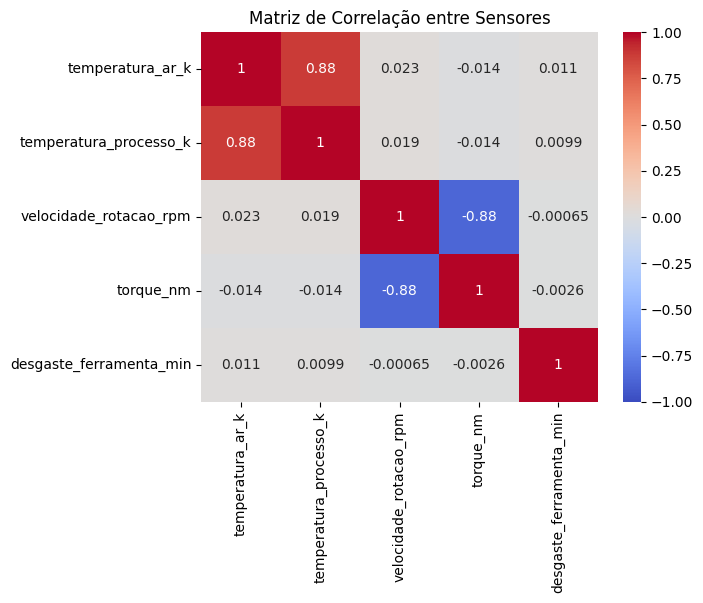

In [47]:
import seaborn as sns
sensores = dados_maq[["temperatura_ar_k", "temperatura_processo_k", "velocidade_rotacao_rpm", "torque_nm", "desgaste_ferramenta_min"]]
correlacoes = sensores.corr()
sns.heatmap(correlacoes, annot=True, cmap="coolwarm",vmin=-1, vmax=1, center=0)
plt.title("Matriz de Correlação entre Sensores")
plt.show()

O gráfico de correlação possui dois pares que mais se destacam nas suas extremidades, a conclusão vem dos dados e não prova uma relação de causa, porem a temperatura do ar e temperatura do processo seguem uma logica e estão correlacionados, tentendo a aumentar ou diminuir na mesma direção. Já rotação e torque tem uma correlação inversa, rotação maior tende para torque menor e vice-versa.

Nesta base, a correlação entre temperaturas é aproximadamente +0,88 e entre rotação e torque é -0,88. Essas relações são observações dos dados, não regras universais para equipamentos. O desgaste tem pouca relação linear com os outros sensores, mas isso não prova que seja inútil para detectar falhas. A matriz motiva investigar combinações matemáticas de sensores na Fase 3, sem presumir ganho de desempenho.

### Verificação inicial de duplicatas

Conto linhas integralmente repetidas. Medições iguais em registros com identificadores diferentes não são automaticamente duplicatas.

In [48]:
dados_maq.duplicated().sum()

np.int64(0)

## Fase 2 — Limpeza e tratamento dos dados

### Diagnóstico de limpeza e valores extremos

Removo eventuais duplicatas completas em uma cópia, preservando a base original, e confiro a unicidade de `udi`. Comparo média, mediana e assimetria para orientar o preenchimento. Os boxplots são separados porque os sensores têm unidades e escalas diferentes. O diagnóstico não preenche nulos nem exclui candidatos a valores extremos.

Registros originais: 10000
Registros após remover duplicatas: 10000
Identificadores udi repetidos: 0

Valores ausentes:
temperatura_ar_k          500
temperatura_processo_k    500
velocidade_rotacao_rpm    500
torque_nm                 500
dtype: int64


,media,mediana,assimetria
temperatura_ar_k,300.002,300.1,0.115
temperatura_processo_k,310.001,310.1,0.016
velocidade_rotacao_rpm,1539.245,1504.0,1.995
torque_nm,39.974,40.1,-0.008


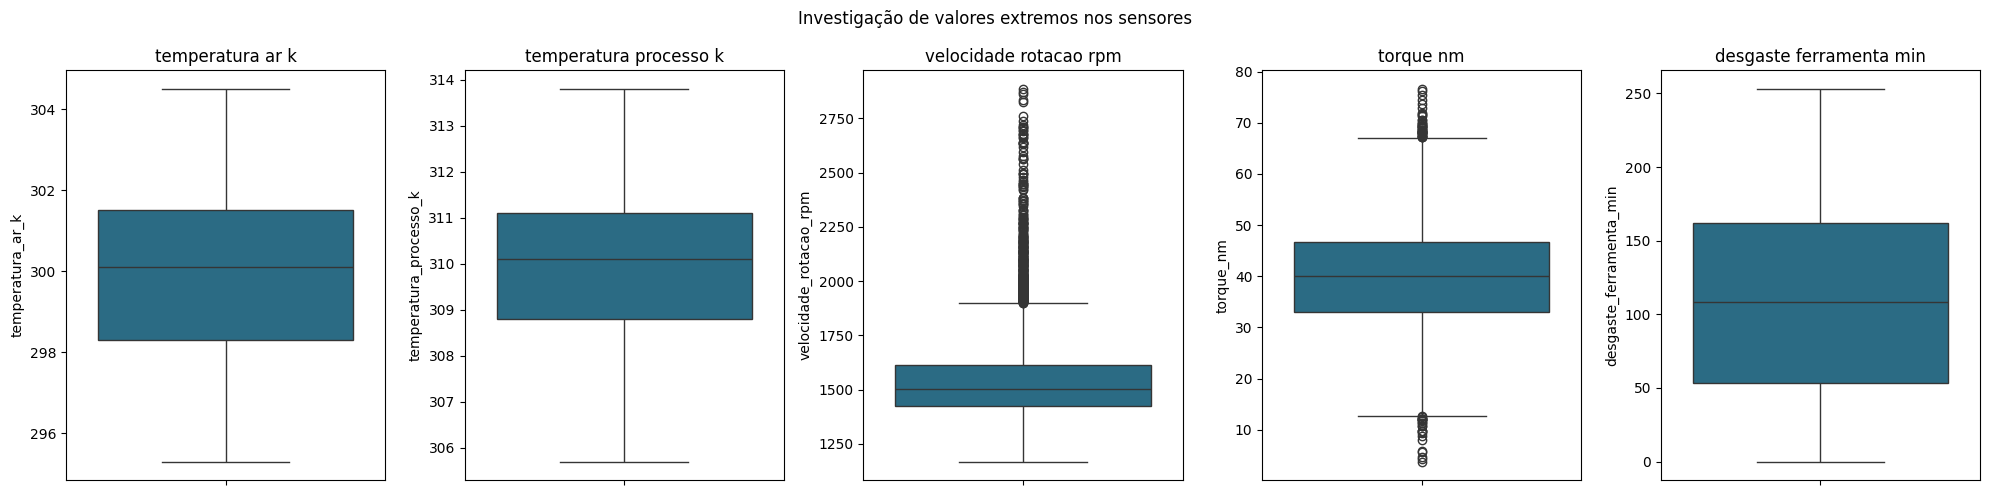

In [49]:
dados_tratados = dados_maq.drop_duplicates().copy()

print("Registros originais:", len(dados_maq))
print("Registros após remover duplicatas:", len(dados_tratados))
print("Identificadores udi repetidos:",
      dados_tratados.duplicated(subset=["udi"]).sum())

colunas_com_nulos = [
    "temperatura_ar_k",
    "temperatura_processo_k",
    "velocidade_rotacao_rpm",
    "torque_nm"
]

print("\nValores ausentes:")
print(dados_tratados[colunas_com_nulos].isna().sum())

resumo_tratamento = pd.DataFrame({
    "media": dados_tratados[colunas_com_nulos].mean(),
    "mediana": dados_tratados[colunas_com_nulos].median(),
    "assimetria": dados_tratados[colunas_com_nulos].skew()
})

display(resumo_tratamento.round(3))

colunas_sensores = colunas_com_nulos + ["desgaste_ferramenta_min"]

fig, axes = plt.subplots(1, 5, figsize=(20, 5))

for eixo, coluna in zip(axes, colunas_sensores):
    sns.boxplot(
        data=dados_tratados,
        y=coluna,
        ax=eixo,
        color="#1C7293"
    )
    eixo.set_title(coluna.replace("_", " "))
    eixo.set_ylabel(coluna)

fig.suptitle("Investigação de valores extremos nos sensores")
plt.tight_layout()
plt.show()

Não foram encontradas duplicatas completas nem identificadores `udi` repetidos; permanecem 10.000 registros. Os boxplots mostram candidatos a valores extremos principalmente em rotação e torque. Preservo esses registros porque não há evidência suficiente de erro e eles podem representar condições relevantes para falhas. Pontos além dos prolongamentos não significam automaticamente erro nem falha.

### Imputação após divisão antecipada

Anteciparei a divisão estratificada 80/20 da Fase 4 para calcular valores de preenchimento somente no treino. A média será usada nas temperaturas e no torque pela baixa assimetria e proximidade entre média e mediana; a mediana será usada na rotação pela cauda à direita e assimetria próxima de 1,995. Os mesmos valores aprendidos no treino serão aplicados ao teste. As cópias evitam alterar a base original.

A divisão será reutilizada nas fases seguintes, sem uma segunda separação. A nova variável será calculada em cada conjunto depois de preencher os nulos. **Resultado:** no Colab, o preenchimento foi executado com 8.000 registros de treino e 2.000 de teste, sem ausências restantes nos sensores. A mudança de ambiente ocorreu porque o Smart App Control bloqueou a importação do scikit-learn no Windows.

In [50]:
from sklearn.model_selection import train_test_split

dados_treino, dados_teste = train_test_split(
    dados_tratados,
    test_size=0.20,
    stratify=dados_tratados["falha_maquina"],
    random_state=42
)

dados_treino = dados_treino.copy()
dados_teste = dados_teste.copy()

estrategias = {
    "temperatura_ar_k": "media",
    "temperatura_processo_k": "media",
    "velocidade_rotacao_rpm": "mediana",
    "torque_nm": "media"
}

valores_preenchimento = {}

for coluna, estrategia in estrategias.items():
    if estrategia == "media":
        valor = dados_treino[coluna].mean()
    else:
        valor = dados_treino[coluna].median()

    valores_preenchimento[coluna] = valor

    dados_treino[coluna] = dados_treino[coluna].fillna(valor)
    dados_teste[coluna] = dados_teste[coluna].fillna(valor)

print("Valores de preenchimento calculados somente no treino:")
display(pd.Series(valores_preenchimento, name="valor"))

print("Registros de treino:", len(dados_treino))
print("Registros de teste:", len(dados_teste))

print("\nAusentes nos sensores do treino:")
print(dados_treino[colunas_sensores].isna().sum())

print("\nAusentes nos sensores do teste:")
print(dados_teste[colunas_sensores].isna().sum())

Valores de preenchimento calculados somente no treino:


,valor
temperatura_ar_k,300.002741
temperatura_processo_k,310.000738
velocidade_rotacao_rpm,1503.500000
torque_nm,39.997733


Registros de treino: 8000
Registros de teste: 2000

Ausentes nos sensores do treino:
temperatura_ar_k           0
temperatura_processo_k     0
velocidade_rotacao_rpm     0
torque_nm                  0
desgaste_ferramenta_min    0
dtype: int64

Ausentes nos sensores do teste:
temperatura_ar_k           0
temperatura_processo_k     0
velocidade_rotacao_rpm     0
torque_nm                  0
desgaste_ferramenta_min    0
dtype: int64


## Fase 3 — Feature Engineering

Crio a variável `potencia_mecanica_w`, combinando torque e velocidade de rotação. Pela relação física entre potência, torque e velocidade angular, converto a rotação de RPM para radianos por segundo usando o fator 2π/60.

As ausências foram preenchidas anteriormente usando informações exclusivamente do treino. Aplico a mesma fórmula separadamente ao treino e ao teste, preservando a divisão existente.

A nova variável atende ao requisito de combinação matemática entre colunas. Seu benefício para a classificação ainda precisa ser avaliado.

In [51]:
import numpy as np

for conjunto in [dados_treino, dados_teste]:
    conjunto["potencia_mecanica_w"] = (
        conjunto["torque_nm"]
        * conjunto["velocidade_rotacao_rpm"]
        * (2 * np.pi / 60)
    )

colunas_potencia = [
    "velocidade_rotacao_rpm",
    "torque_nm",
    "potencia_mecanica_w"
]

display(dados_treino[colunas_potencia].head().round(2))

for nome, conjunto in [
    ("Treino", dados_treino),
    ("Teste", dados_teste)
]:
    valores = conjunto["potencia_mecanica_w"]

    print(
        f"{nome}: "
        f"{valores.isna().sum()} valores ausentes; "
        f"{(~np.isfinite(valores)).sum()} valores não finitos."
    )

,velocidade_rotacao_rpm,torque_nm,potencia_mecanica_w
4058,1503.5,40.0,6297.49
1221,1399.0,46.4,6797.74
6895,1357.0,45.6,6479.97
9863,1411.0,56.3,8318.86
8711,1733.0,28.7,5208.46


Treino: 0 valores ausentes; 0 valores não finitos.
Teste: 0 valores ausentes; 0 valores não finitos.


## Fase 4 — Divisão e balanceamento dos dados

Nesta versão, uso como entradas as cinco medições dos sensores e a potência mecânica calculada. A resposta que o modelo deverá aprender é `falha_maquina`.

Não uso `udi` e `id_produto`, pois são identificadores, nem as cinco colunas de causas de falha, que entregariam informações posteriores ao evento. A categoria `tipo` também fica fora desta versão, que concentra a análise nas medições numéricas.

Reutilizo a divisão de 80% para treino e 20% para teste, feita anteriormente com estratificação. Não faço outra divisão, pois os valores de preenchimento já foram calculados usando aquele treino.

Como há poucas falhas, aplico SMOTE somente no treino. Ele gera exemplos sintéticos da classe minoritária. O teste mantém seus registros e sua proporção de classes, sem balanceamento.

In [52]:
from imblearn.over_sampling import SMOTE

colunas_preditoras = [
    "temperatura_ar_k",
    "temperatura_processo_k",
    "velocidade_rotacao_rpm",
    "torque_nm",
    "desgaste_ferramenta_min",
    "potencia_mecanica_w"
]

# Reutiliza os conjuntos divididos e tratados anteriormente.
X_train = dados_treino[colunas_preditoras].copy()
X_test = dados_teste[colunas_preditoras].copy()

y_train = dados_treino["falha_maquina"].copy()
y_test = dados_teste["falha_maquina"].copy()

print("Variáveis preditoras:", list(X_train.columns))
print("\nTreino antes do balanceamento:", X_train.shape)
display(y_train.value_counts().sort_index())

print("\nTeste:", X_test.shape)
display(y_test.value_counts().sort_index())

# Somente os dados de treino entram no SMOTE.
smote = SMOTE(random_state=42)

X_train_bal, y_train_bal = smote.fit_resample(
    X_train, y_train
)

print("\nTreino depois do SMOTE:", X_train_bal.shape)
display(y_train_bal.value_counts().sort_index())

print("\nPercentuais depois do SMOTE:")
display(y_train_bal.value_counts(normalize=True).sort_index() * 100)

print("\nTeste permanece com:", len(y_test), "registros")
display(y_test.value_counts().sort_index())

Variáveis preditoras: ['temperatura_ar_k', 'temperatura_processo_k', 'velocidade_rotacao_rpm', 'torque_nm', 'desgaste_ferramenta_min', 'potencia_mecanica_w']

Treino antes do balanceamento: (8000, 6)


,count
falha_maquina,
0,7729
1,271



Teste: (2000, 6)


,count
falha_maquina,
0,1932
1,68



Treino depois do SMOTE: (15458, 6)


,count
falha_maquina,
0,7729
1,7729



Percentuais depois do SMOTE:


,proportion
falha_maquina,
0,50.0
1,50.0



Teste permanece com: 2000 registros


,count
falha_maquina,
0,1932
1,68


## Fase 5 — Escalonamento das variáveis

O KNN compara distâncias entre registros. Como os sensores têm escalas diferentes, uso StandardScaler nas variáveis contínuas para evitar que os valores de maior escala dominem essa comparação.

O escalonador aprende somente no treino com fit_transform. No teste, uso apenas transform, reaproveitando os parâmetros do treino.

A Árvore de Decisão usará os dados sem escalonamento, pois seus cortes dependem da ordem dos valores de cada variável, que é preservada pelo StandardScaler.

In [53]:
from sklearn.preprocessing import StandardScaler

# As seis entradas selecionadas são tratadas como variáveis contínuas.
colunas_continuas = colunas_preditoras.copy()

scaler = StandardScaler()

# Cópias exclusivas para o KNN.
X_train_knn = X_train_bal.copy()
X_test_knn = X_test.copy()

X_train_knn[colunas_continuas] = scaler.fit_transform(
    X_train_bal[colunas_continuas]
)

X_test_knn[colunas_continuas] = scaler.transform(
    X_test[colunas_continuas]
)

print("Médias do treino após escalonamento:")
display(X_train_knn[colunas_continuas].mean().round(6))

print("\nPrimeiros registros do treino escalonado:")
display(X_train_knn.head().round(3))

print("\nFormato do treino KNN:", X_train_knn.shape)
print("Formato do teste KNN:", X_test_knn.shape)

print("\nDados da árvore permanecem sem escalonamento:")
display(X_train_bal.head().round(3))

Médias do treino após escalonamento:


,0
temperatura_ar_k,0.0
temperatura_processo_k,0.0
velocidade_rotacao_rpm,-0.0
torque_nm,0.0
desgaste_ferramenta_min,0.0
potencia_mecanica_w,-0.0



Primeiros registros do treino escalonado:


,temperatura_ar_k,temperatura_processo_k,velocidade_rotacao_rpm,torque_nm,desgaste_ferramenta_min,potencia_mecanica_w
0,-0.213,-0.114,-0.059,-0.329,-1.026,-0.289
1,-1.810,-1.432,-0.415,0.124,0.106,0.034
2,0.318,1.127,-0.558,0.067,0.178,-0.171
3,-0.799,-0.269,-0.374,0.824,-0.591,1.016
4,-1.757,-1.277,0.722,-1.127,-1.084,-0.992



Formato do treino KNN: (15458, 6)
Formato do teste KNN: (2000, 6)

Dados da árvore permanecem sem escalonamento:


,temperatura_ar_k,temperatura_processo_k,velocidade_rotacao_rpm,torque_nm,desgaste_ferramenta_min,potencia_mecanica_w
0,300.003,310.001,1503.5,39.998,54,6297.489
1,297.000,308.300,1399.0,46.400,132,6797.736
2,301.000,311.600,1357.0,45.600,137,6479.975
3,298.900,309.800,1411.0,56.300,84,8318.864
4,297.100,308.500,1733.0,28.700,50,5208.457


## Fase 6 — Ajuste de parâmetros e análise de overfitting

Testo o KNN com K igual a 3, 5 e 7, usando os dados escalonados. Na Árvore de Decisão, testo profundidades máximas de 3, 5 e sem limite, usando os dados sem escalonamento.

Para cada configuração, comparo a acurácia no treino e no teste. Um resultado muito alto no treino acompanhado de desempenho inferior no teste pode indicar overfitting. Os resultados são interpretados abaixo, após as tabelas e o gráfico.

In [54]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

# KNN: três valores ímpares de K.
resultados_knn = []

for k in [3, 5, 7]:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train_knn, y_train_bal)

    acc_treino = accuracy_score(
        y_train_bal, knn.predict(X_train_knn)
    )
    acc_teste = accuracy_score(
        y_test, knn.predict(X_test_knn)
    )

    resultados_knn.append({
        "k": k,
        "acuracia_treino": acc_treino,
        "acuracia_teste": acc_teste
    })

resultados_knn = pd.DataFrame(resultados_knn)

print("Resultados do KNN:")
display(resultados_knn.round(4))

# Árvore: três limites de profundidade.
resultados_arvore = []

for profundidade in [3, 5, None]:
    arvore = DecisionTreeClassifier(
        max_depth=profundidade,
        random_state=42
    )
    arvore.fit(X_train_bal, y_train_bal)

    acc_treino = accuracy_score(
        y_train_bal, arvore.predict(X_train_bal)
    )
    acc_teste = accuracy_score(
        y_test, arvore.predict(X_test)
    )

    resultados_arvore.append({
        "max_depth": profundidade,
        "acuracia_treino": acc_treino,
        "acuracia_teste": acc_teste
    })

resultados_arvore = pd.DataFrame(resultados_arvore)

print("\nResultados da Árvore de Decisão:")
display(resultados_arvore.round(4))

Resultados do KNN:


,k,acuracia_treino,acuracia_teste
0,3,0.9677,0.9185
1,5,0.9591,0.9085
2,7,0.9519,0.9030



Resultados da Árvore de Decisão:


,max_depth,acuracia_treino,acuracia_teste
0,3.0,0.8683,0.871
1,5.0,0.9183,0.909
2,NaN,0.9896,0.939


### Comparação visual das configurações

Uso duas curvas, treino e teste, para cada modelo. O gráfico ajuda a comparar o desempenho e a diferença entre os conjuntos conforme altero K ou a profundidade. Não comparo as alturas das figuras pela aparência: leio os valores de acurácia, pois os eixos têm limites diferentes.

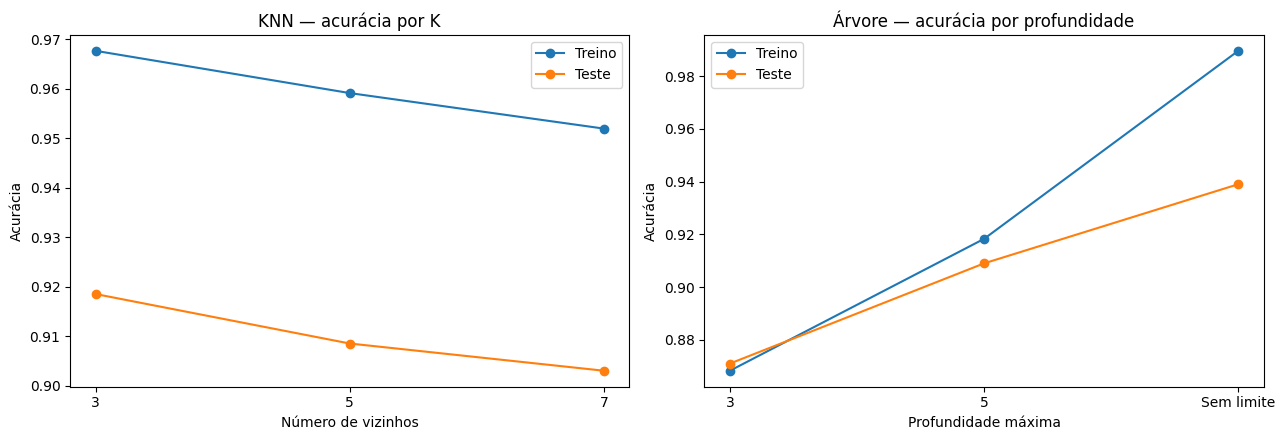

In [55]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(
    resultados_knn["k"], resultados_knn["acuracia_treino"],
    marker="o", label="Treino"
)
axes[0].plot(
    resultados_knn["k"], resultados_knn["acuracia_teste"],
    marker="o", label="Teste"
)
axes[0].set_title("KNN — acurácia por K")
axes[0].set_xlabel("Número de vizinhos")
axes[0].set_xticks([3, 5, 7])

rotulos = ["3", "5", "Sem limite"]

axes[1].plot(
    rotulos, resultados_arvore["acuracia_treino"],
    marker="o", label="Treino"
)
axes[1].plot(
    rotulos, resultados_arvore["acuracia_teste"],
    marker="o", label="Teste"
)
axes[1].set_title("Árvore — acurácia por profundidade")
axes[1].set_xlabel("Profundidade máxima")

for eixo in axes:
    eixo.set_ylabel("Acurácia")
    eixo.legend()

plt.tight_layout()
plt.show()

### Interpretação dos resultados

No KNN, K=3 apresentou 96,77% de acurácia no treino e 91,85% no teste. K=5 teve 95,91% e 90,85%; K=7 teve 95,19% e 90,30%. Aumentar K reduziu os dois resultados e não melhorou o teste. Entre as configurações testadas, K=3 teve o melhor desempenho no teste. A diferença entre treino e teste ficou próxima de cinco pontos percentuais nos três casos, indicando uma perda de desempenho fora do treino.

Na árvore, profundidade 3 teve 86,83% no treino e 87,10% no teste. Profundidade 5 teve 91,83% e 90,90%. Sem limite, a árvore chegou a 98,96% no treino e 93,90% no teste. A configuração sem limite apresentou a maior diferença, de aproximadamente 5,06 pontos percentuais, um indício de sobreajuste. Ainda assim, sua acurácia no teste foi a maior: neste experimento, aumentar a profundidade também melhorou o teste.

A árvore com profundidade 3 teve as acurácias mais próximas, mas menor desempenho. A profundidade 5 mostrou um equilíbrio entre acurácia e diferença dos conjuntos, com cerca de 0,93 ponto percentual de diferença. Para a comparação final pelo critério solicitado no projeto, seleciono K=3 e a árvore sem limite de profundidade, pois tiveram as maiores acurácias no teste em cada modelo.

Essa comparação usa um treino balanceado e um teste com a proporção original de classes. Portanto, a diferença de acurácia é um sinal a interpretar com cuidado, não uma prova isolada de sobreajuste. Os resultados mostram uma única divisão dos dados; proximidade entre as curvas não comprova estabilidade em outras divisões.

Na tabela, `NaN` em `max_depth` representa o parâmetro `None`, ou seja, sem limite de profundidade. Não é um valor ausente nas medições dos sensores.


## Fase 7 — Avaliação e veredito final

Seleciono a configuração com maior acurácia no teste para cada modelo. Treino novamente o melhor KNN com os dados escalonados e a melhor árvore com os dados sem escalonamento.

Comparo os resultados no mesmo conjunto de teste e escolho o modelo com maior acurácia, conforme solicitado no projeto.

In [56]:
# Seleciona o melhor KNN pela maior acurácia no teste.
melhor_k = int(
    resultados_knn.loc[
        resultados_knn["acuracia_teste"].idxmax(), "k"
    ]
)

# Na tabela, None pode aparecer como NaN.
profundidade_selecionada = resultados_arvore.loc[
    resultados_arvore["acuracia_teste"].idxmax(), "max_depth"
]

melhor_profundidade = (
    None
    if pd.isna(profundidade_selecionada)
    else int(profundidade_selecionada)
)

# Treina e avalia os modelos selecionados.
knn_final = KNeighborsClassifier(n_neighbors=melhor_k)
knn_final.fit(X_train_knn, y_train_bal)
pred_knn = knn_final.predict(X_test_knn)

arvore_final = DecisionTreeClassifier(
    max_depth=melhor_profundidade,
    random_state=42
)
arvore_final.fit(X_train_bal, y_train_bal)
pred_arvore = arvore_final.predict(X_test)

acc_knn = accuracy_score(y_test, pred_knn)
acc_arvore = accuracy_score(y_test, pred_arvore)

print("Melhor K:", melhor_k)
print("Melhor profundidade:", melhor_profundidade)
print(f"\nAcurácia final do KNN: {acc_knn:.2%}")
print(f"Acurácia final da árvore: {acc_arvore:.2%}")

if acc_arvore > acc_knn:
    print("\nModelo selecionado pela acurácia: Árvore de Decisão")
elif acc_knn > acc_arvore:
    print("\nModelo selecionado pela acurácia: KNN")
else:
    print("\nOs modelos empataram em acurácia.")

Melhor K: 3
Melhor profundidade: None

Acurácia final do KNN: 91.85%
Acurácia final da árvore: 93.90%

Modelo selecionado pela acurácia: Árvore de Decisão


### Conclusão

Entre as configurações testadas, o melhor KNN foi K=3, com 91,85% de acurácia no teste. A melhor Árvore de Decisão foi a configuração sem limite de profundidade, com 93,90%.

Pelo critério solicitado no projeto, seleciono a Árvore de Decisão, que apresentou maior acurácia no mesmo conjunto de teste. Ela teve vantagem de 2,05 pontos percentuais sobre o KNN.

A árvore sem limite também apresentou indício de sobreajuste: a acurácia no treino foi 98,96%, superior aos 93,90% do teste. Ainda assim, foi a configuração com melhor resultado no teste entre as avaliadas.

Como existem muito mais registros normais do que falhas, a acurácia não informa, sozinha, quantas falhas foram identificadas. Essa é uma limitação da conclusão e não permite afirmar que o modelo já está pronto para uso na fábrica.